In [1]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import paths, plots
from common.data import read_csv, show_dataset

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios

DATA_DIR = paths.RAW
OUT_DIR = paths.PROCESSED

plots.aplicar_estilo()

print(f"dados em {DATA_DIR}")
print(f"saida em {OUT_DIR}")
print(f"semente: {SEED}")


dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
saida em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\processed
semente: 42


In [2]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee*.csv")) # utilizar apena dados dos inversores e.x
)
CAMINHOS = {p.stem: p for p in ARQUIVOS}   # para re-conferir contra o CSV bruto no fim
print(f"{len(ARQUIVOS)} arquivos" + NL)

STATIONS = [f.stem.split('_')[0] for f in ARQUIVOS if f.exists()]

partes: list[pd.DataFrame] = []

for p in ARQUIVOS:
    df = read_csv(p, parse=("datetime", "timestamp"))
    df["station"] = p.stem.split("_")[0]
    partes.append(df)

    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

9 arquivos

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [3]:
raw = raw.drop(columns=[c for c in raw.columns if c in {"condicao", "velocidade_vento", "timestamp"}])
d = raw.copy()
d.PCA = d.PCA.fillna(0)
df = show_dataset(d.copy(), colunas=True)

del d


pool: 410451 linhas, 16 colunas
colunas: ['PCA', 'angzen', 'datetime', 'doy', 'ghi_cs', 'ghit', 'hora_dec', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'station', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9683


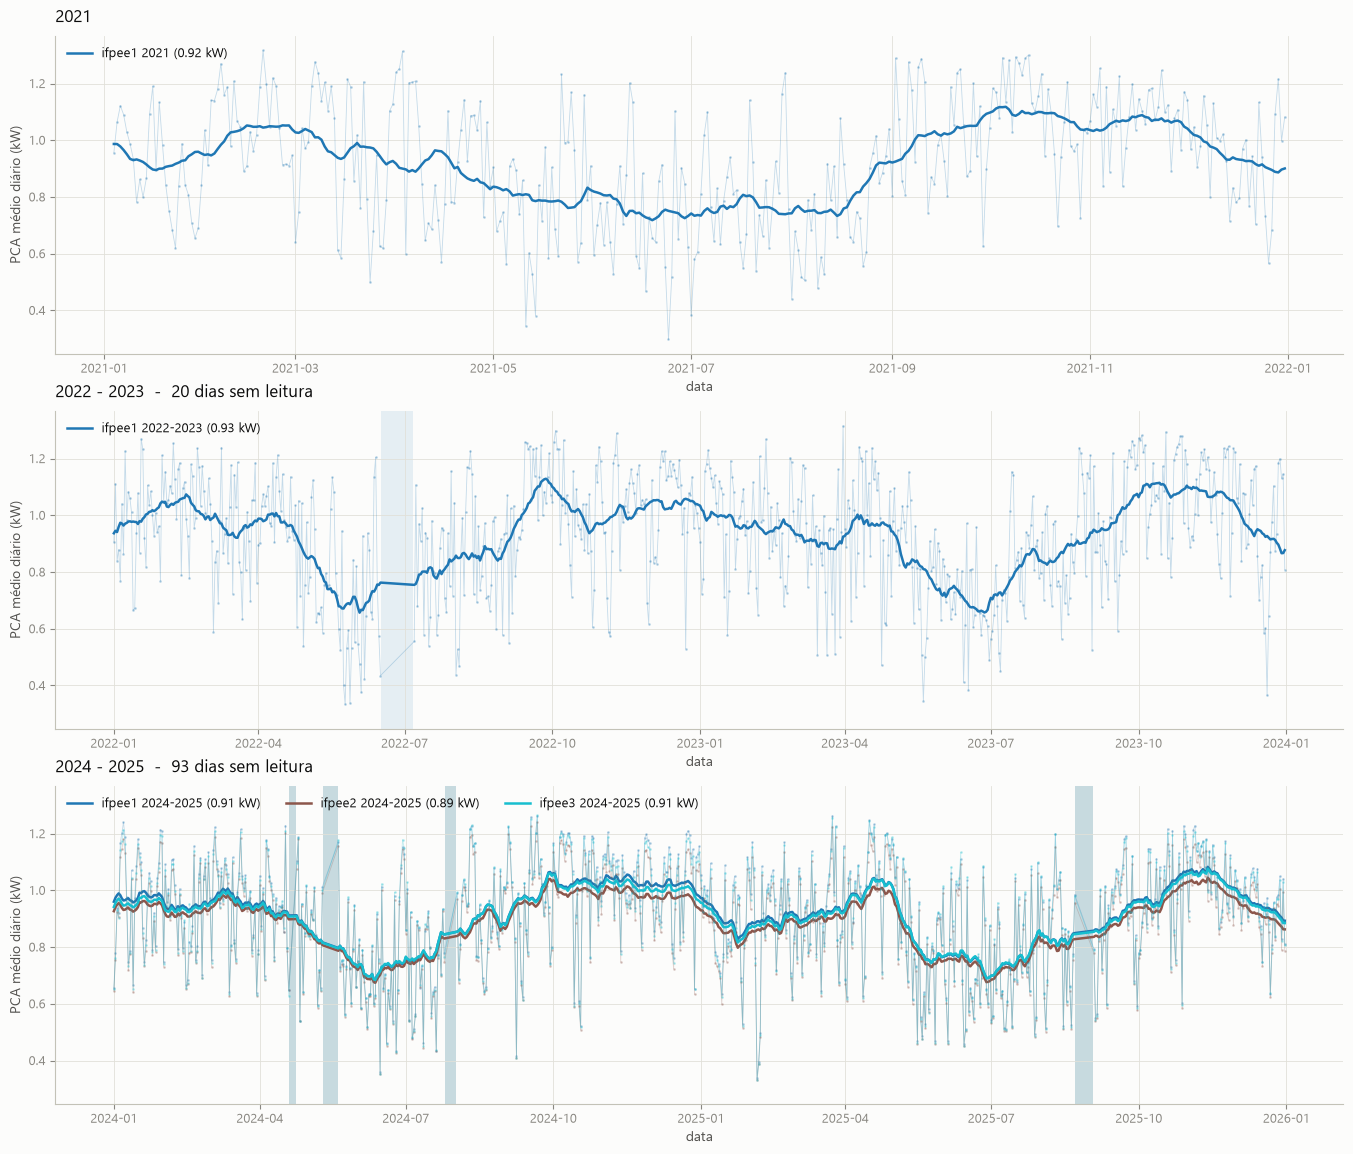

In [4]:
plots.plot_time_series(df.reset_index(), janela=30)

## Downsampling dataset

In [5]:
regras = {
    'PCA': 'mean',
    'ghit': 'mean',
    'ioeff': 'mean',
    'jacques': 'mean',
    'kc': 'mean',
    'kt': 'mean',
    'pvsyst_cell': 'mean',
    'sandia': 'mean',
    'sandia_cell': 'mean',
    'temperatura_ambiente': 'mean',
}

# Downsample dataset (1d period)
def downsample(df: pd.DataFrame, rules, freq='1D', limiar_zero=0.15):

    d = df.copy().reset_index(drop=True)
    dia = d["datetime"].dt.normalize()
    chave = [d["station"], dia]

    # Ainda há mais de uma leitura por estação/dia?
    if d.groupby(chave).size().gt(1).any():
        diurno = d["datetime"].dt.hour.between(6, 17)

        # Condição de leitura inválida. Ajuste aqui se necessário.
        invalido = d["PCA"].isna() | d["PCA"].eq(0)

        # Fração de leituras inválidas restritas ao período diurno de cada
        # estação/dia. Com amostragem regular, a fração de leituras equivale
        # à fração de tempo dentro da janela.
        zeros_diurno = (invalido & diurno).groupby(chave).transform("sum")
        total_diurno = diurno.groupby(chave).transform("sum")

        frac_zero = zeros_diurno / total_diurno.where(total_diurno > 0)

        # Descarta somente quando MAIS de 15% das leituras diurnas estão zeradas.
        descartar = frac_zero > limiar_zero
        tem_diurno = total_diurno > 0

        d = d.loc[tem_diurno & ~descartar]
    else:
        # Fallback para quando a célula é reexecutada com df já diário.
        d = d.loc[d["PCA"].notna() & d["PCA"].ne(0)]

    return show_dataset(
        d.groupby(['station', pd.Grouper(key='datetime', freq=freq)])
        .agg(rules)
        .reset_index(),
        colunas=True,
    )

df = downsample(df, regras)



pool: 3154 linhas, 12 colunas
colunas: ['PCA', 'datetime', 'ghit', 'ioeff', 'jacques', 'kc', 'kt', 'pvsyst_cell', 'sandia', 'sandia_cell', 'station', 'temperatura_ambiente']

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
  (nenhum)


In [10]:
def min_max_normalize(dataset: pd.DataFrame, *keys):
    df = dataset.copy()
    for key in keys:
        df[key] = (df[key] - df[key].min()) / (
            df[key].max() - df[key].min()
        )   
    
    return df
df = min_max_normalize(df, *df.columns.drop(["datetime", "station"]))

In [11]:
if not OUT_DIR.exists():
  OUT_DIR.mkdir()

# CSVs por estacao em data/processed/ -- sao a entrada do split (feito a mao, em
# outro notebook). Nao gravar nada aqui que nao seja o resultado FINAL do prep.
for s, f in df.groupby('station'):
  f.drop(columns=['station']).to_csv(OUT_DIR / f"{s}.csv", index=False)
  print(f"{s}.csv: {len(f)} linhas, {f.shape[1]} colunas")

ifpee1.csv: 1763 linhas, 12 colunas
ifpee2.csv: 696 linhas, 12 colunas
ifpee3.csv: 695 linhas, 12 colunas
